# Olist Seller Acquisition → 90-Day Marketplace Value

This notebook is a reproducible report over the pipeline outputs in `data/processed/`. Run `python -m src.pipeline` from the repository root first. Raw source records are intentionally excluded from this distributable package; users must obtain the licensed sources separately, place them in the configured data folders, and rerun the pipeline.

**Observation design:** seller deals are mature only when their full 90-day window ends on or before the exclusive observation boundary, `data_end`. The active rule requires at least 50 marketplace orders per calendar day. Unlinked seller outcomes remain unobserved, not zero. Channel origin is observational.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data" / "processed").exists():
    ROOT = Path(__file__).resolve().parents[1]
OUT = ROOT / "data" / "processed"
CHARTS = ROOT / "reports" / "charts"

def read(name):
    path = OUT / f"{name}.csv"
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. Run `python -m src.pipeline` first.")
    return pd.read_csv(path)

validation = read("validation_summary")
seller = read("seller_90d_value")
channels = read("channel_90d_summary")
pairs = read("pairwise_comparisons")
inferential = read("inferential_tests")
linkage = read("linkage_diagnostics")
ipw = read("ipw_activation_by_origin")
sensitivity = read("maturity_sensitivity")
window_sensitivity = read("window_sensitivity")
logit = read("activation_logistic_regression")
conversion_lead = read("conversion_by_lead_type")
conversion_segment = read("conversion_by_business_segment")
close_days = read("median_days_to_close_by_origin")
gmv_concentration = read("gmv_concentration")
lorenz = read("gmv_lorenz_curve")
payment = read("gmv_and_payment_checks")
print(f"Loaded {len(seller):,} deal rows; data_end = {seller['data_end'].iloc[0]}")

Loaded 842 deal rows; data_end = 2018-08-28


## 1. Cohort boundary, maturity and data quality

The exclusive observation boundary prevents a sparse late tail from making 90-day windows appear mature. The sensitivity table shows the effect of 10-, 50- and 100-orders/day cutoff rules.

In [2]:
display(validation)
display(sensitivity)
key_checks = validation[validation["check"].astype(str).str.contains("data_end|mature|outside|delivery|close", case=False, regex=True)]
display(key_checks)

,check,value,detail
0,lead_mql_id_unique,True,duplicate keys=0
1,deal_mql_id_unique,True,duplicate keys=0
2,closed_deal_seller_id_unique,True,duplicate seller IDs=0
3,order_id_unique,True,duplicate keys=0
4,order_item_composite_key_unique,True,"Duplicate (order_id, order_item_id) rows"
5,deals_with_matching_lead_pct,100.0,Share of deal rows with matching qualified-lea...
6,order_items_with_matching_order_pct,100.0,Share of order-item rows with matching order r...
7,max_order_purchase_timestamp,2018-10-17 17:30:18,Absolute latest purchase timestamp; includes s...
8,last_qualifying_purchase_day,2018-08-27 00:00:00,Last day with at least 50 orders
9,data_end,2018-08-28 00:00:00,Exclusive maturity boundary: qualifying day + ...


,min_orders_per_day,data_end_exclusive,mature_90d_deals,rule
0,10,2018-08-30,665,day after latest calendar date with at least t...
1,50,2018-08-28,656,day after latest calendar date with at least t...
2,100,2018-08-24,654,day after latest calendar date with at least t...


,check,value,detail
2,closed_deal_seller_id_unique,True,duplicate seller IDs=0
9,data_end,2018-08-28 00:00:00,Exclusive maturity boundary: qualifying day + ...
11,orders_outside_data_end,83,Raw order records with purchase timestamp >= e...
12,mature_windows_ending_after_data_end,0,Must equal zero
16,delivered_orders_without_delivery_date,8,Delivered status but no customer-delivery time...
17,non_delivered_orders_with_delivery_date,6,Non-delivered status but customer-delivery tim...
19,closed_deal_sellers_found_in_order_items_count,380,Closed-deal seller IDs present in any order-it...
20,closed_deal_sellers_found_in_order_items_pct,45.13,Cross-dataset linkage rate; unmatched sellers ...
21,mature_seller_deals,656,Deals with complete 90-day purchase observatio...
22,mature_seller_deals_linked_to_order_items_count,340,Mature deals with seller ID appearing in order...


## 2. Seller linkage and selection

Marketplace outcomes are observable only for deals linked to order-item seller IDs. The linkage tables describe coverage by origin, lead type, business segment and win month. IPW is a sensitivity analysis under a measured-selection assumption; it does not recover outcomes for unlinked sellers or remove unmeasured bias.

In [3]:
display(linkage.pivot_table(index="dimension", columns="group_value", values=["mature_deals", "linked_deals", "linkage_rate_pct"], aggfunc="first").T if False else linkage)
display(ipw)

,dimension,group_value,mature_deals,linked_deals,unlinked_deals,linkage_rate_pct
0,origin,(missing),11,4,7,36.363636
1,origin,direct_traffic,49,28,21,57.142857
2,origin,display,6,2,4,33.333333
3,origin,email,12,6,6,50.000000
4,origin,organic_search,204,103,101,50.490196
5,origin,other,4,2,2,50.000000
6,origin,other_publicities,3,0,3,0.000000
7,origin,paid_search,144,87,57,60.416667
8,origin,referral,18,9,9,50.000000
9,origin,social,55,26,29,47.272727


,origin,linked_mature_n,observed_activated_n,observed_activation_pct,ipw_activation_pct,ipw_effective_sample_size,mean_stabilized_ipw,ipw_99pct_cap
0,(missing),4,3,75.000000,73.589925,3.578578,1.187173,2.330626
1,direct_traffic,28,22,78.571429,75.263843,25.870512,0.922715,2.330626
2,display,2,1,50.000000,43.124488,1.962884,1.127311,2.330626
3,email,6,5,83.333333,81.571477,5.968159,0.815656,2.330626
4,organic_search,103,80,77.669903,79.643476,91.563292,1.004014,2.330626
5,other,2,1,50.000000,43.847832,1.970172,0.720888,2.330626
6,paid_search,87,79,90.804598,90.461362,78.951523,0.866232,2.330626
7,referral,9,8,88.888889,84.950366,7.663423,1.136878,2.330626
8,social,26,24,92.307692,94.684384,22.121129,1.122553,2.330626
9,unknown,73,59,80.821918,79.078305,64.185493,1.043284,2.330626


## 3. Activation: pairwise uncertainty and omnibus test

Pairwise contrasts use Fisher exact tests, Holm adjustment across all eligible origin pairs within each activation definition, and Newcombe confidence intervals for differences in proportions. The global five-origin comparison uses a Monte Carlo fixed-margin test because the expected-cell conditions for the ordinary Pearson approximation are not met.

,outcome,definition,test,origin_a,origin_b,groups_included,n,successes_a,n_a,rate_a_pct,successes_b,n_b,rate_b_pct,risk_difference_a_minus_b_pp,risk_difference_ci_95_low_pp,risk_difference_ci_95_high_pp,odds_ratio,p_value,p_value_holm_adjusted,primary_comparison,minimum_expected_cell,interpretation,statistic,degrees_of_freedom,effect_size,effect_size_name
4,purchase_window:paid_search_vs_organic_search,purchase_window,Fisher exact (two-sided),paid_search,organic_search,paid_search;organic_search,190,79.0,87.0,90.804598,80.0,103.0,77.669903,13.134695,2.593343,23.138979,2.839062,0.017726,0.177265,True,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
1,purchase_window:direct_traffic_vs_paid_search,purchase_window,Fisher exact (two-sided),direct_traffic,paid_search,direct_traffic;paid_search,115,22.0,28.0,78.571429,79.0,87.0,90.804598,-12.233169,-30.884793,1.493421,0.371308,0.101690,0.915212,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
5,purchase_window:organic_search_vs_social,purchase_window,Fisher exact (two-sided),organic_search,social,organic_search;social,129,80.0,103.0,77.669903,24.0,26.0,92.307692,-14.637789,-25.175971,3.225011,0.289855,0.104163,0.915212,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
8,purchase_window:paid_search_vs_unknown,purchase_window,Fisher exact (two-sided),paid_search,unknown,paid_search;unknown,160,79.0,87.0,90.804598,59.0,73.0,80.821918,9.982680,-0.848517,21.370691,2.343220,0.105138,0.915212,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
0,purchase_window:direct_traffic_vs_organic_search,purchase_window,Fisher exact (two-sided),direct_traffic,organic_search,direct_traffic;organic_search,131,22.0,28.0,78.571429,80.0,103.0,77.669903,0.901526,-18.501427,15.253403,1.054167,1.000000,1.000000,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
2,purchase_window:direct_traffic_vs_social,purchase_window,Fisher exact (two-sided),direct_traffic,social,direct_traffic;social,54,22.0,28.0,78.571429,24.0,26.0,92.307692,-13.736264,-32.679617,6.173002,0.305556,0.253099,1.000000,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
3,purchase_window:direct_traffic_vs_unknown,purchase_window,Fisher exact (two-sided),direct_traffic,unknown,direct_traffic;unknown,101,22.0,28.0,78.571429,59.0,73.0,80.821918,-2.250489,-21.812424,13.098044,0.870056,0.786142,1.000000,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
6,purchase_window:organic_search_vs_unknown,purchase_window,Fisher exact (two-sided),organic_search,unknown,organic_search;unknown,176,80.0,103.0,77.669903,59.0,73.0,80.821918,-3.152015,-14.765453,9.428855,0.825350,0.708440,1.000000,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
7,purchase_window:paid_search_vs_social,purchase_window,Fisher exact (two-sided),paid_search,social,paid_search;social,113,79.0,87.0,90.804598,24.0,26.0,92.307692,-1.503095,-11.172436,15.540618,0.822917,1.000000,1.000000,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
9,purchase_window:social_vs_unknown,purchase_window,Fisher exact (two-sided),social,unknown,social;unknown,99,24.0,26.0,92.307692,59.0,73.0,80.821918,11.485774,-6.549590,23.345553,2.847458,0.224877,1.000000,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN


,outcome,definition,test,origin_a,origin_b,groups_included,n,successes_a,n_a,rate_a_pct,successes_b,n_b,rate_b_pct,risk_difference_a_minus_b_pp,risk_difference_ci_95_low_pp,risk_difference_ci_95_high_pp,odds_ratio,p_value,p_value_holm_adjusted,primary_comparison,minimum_expected_cell,interpretation,statistic,degrees_of_freedom,effect_size,effect_size_name
0,purchase_window:direct_traffic_vs_organic_search,purchase_window,Fisher exact (two-sided),direct_traffic,organic_search,direct_traffic;organic_search,131,22.0,28.0,78.571429,80.0,103.0,77.669903,0.901526,-18.501427,15.253403,1.054167,1.000000,1.000000,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
1,purchase_window:direct_traffic_vs_paid_search,purchase_window,Fisher exact (two-sided),direct_traffic,paid_search,direct_traffic;paid_search,115,22.0,28.0,78.571429,79.0,87.0,90.804598,-12.233169,-30.884793,1.493421,0.371308,0.101690,0.915212,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
2,purchase_window:direct_traffic_vs_social,purchase_window,Fisher exact (two-sided),direct_traffic,social,direct_traffic;social,54,22.0,28.0,78.571429,24.0,26.0,92.307692,-13.736264,-32.679617,6.173002,0.305556,0.253099,1.000000,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
3,purchase_window:direct_traffic_vs_unknown,purchase_window,Fisher exact (two-sided),direct_traffic,unknown,direct_traffic;unknown,101,22.0,28.0,78.571429,59.0,73.0,80.821918,-2.250489,-21.812424,13.098044,0.870056,0.786142,1.000000,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
4,purchase_window:paid_search_vs_organic_search,purchase_window,Fisher exact (two-sided),paid_search,organic_search,paid_search;organic_search,190,79.0,87.0,90.804598,80.0,103.0,77.669903,13.134695,2.593343,23.138979,2.839062,0.017726,0.177265,True,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
5,purchase_window:organic_search_vs_social,purchase_window,Fisher exact (two-sided),organic_search,social,organic_search;social,129,80.0,103.0,77.669903,24.0,26.0,92.307692,-14.637789,-25.175971,3.225011,0.289855,0.104163,0.915212,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
6,purchase_window:organic_search_vs_unknown,purchase_window,Fisher exact (two-sided),organic_search,unknown,organic_search;unknown,176,80.0,103.0,77.669903,59.0,73.0,80.821918,-3.152015,-14.765453,9.428855,0.825350,0.708440,1.000000,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
7,purchase_window:paid_search_vs_social,purchase_window,Fisher exact (two-sided),paid_search,social,paid_search;social,113,79.0,87.0,90.804598,24.0,26.0,92.307692,-1.503095,-11.172436,15.540618,0.822917,1.000000,1.000000,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
8,purchase_window:paid_search_vs_unknown,purchase_window,Fisher exact (two-sided),paid_search,unknown,paid_search;unknown,160,79.0,87.0,90.804598,59.0,73.0,80.821918,9.982680,-0.848517,21.370691,2.343220,0.105138,0.915212,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN
9,purchase_window:social_vs_unknown,purchase_window,Fisher exact (two-sided),social,unknown,social;unknown,99,24.0,26.0,92.307692,59.0,73.0,80.821918,11.485774,-6.549590,23.345553,2.847458,0.224877,1.000000,False,NaN,Origin contrast among linked mature deals; obs...,NaN,NaN,NaN,NaN


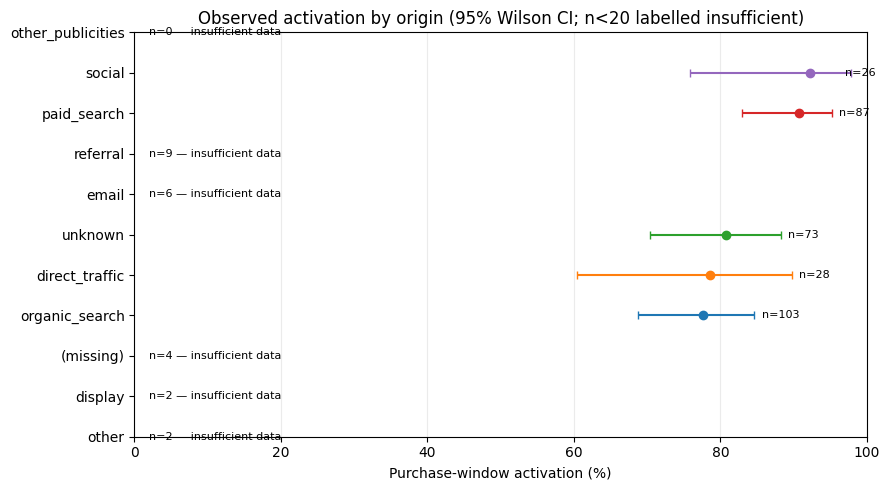

In [4]:
display(pairs.sort_values(["definition", "p_value_holm_adjusted", "origin_a", "origin_b"]))
display(inferential)
fig, ax = plt.subplots(figsize=(9, 5))
plot_df = channels.sort_values("activation_rate_pct")
y = range(len(plot_df))
mid = plot_df["activation_rate_pct"].to_numpy()
lo = plot_df["activation_ci_95_low_pct"].to_numpy()
hi = plot_df["activation_ci_95_high_pct"].to_numpy()
labels = []
for yi, (_, row) in enumerate(plot_df.iterrows()):
    n = int(row["linked_mature_seller_deals"])
    labels.append(row["origin"])
    if n >= 20:
        rate = float(row["activation_rate_pct"])
        low, high = float(row["activation_ci_95_low_pct"]), float(row["activation_ci_95_high_pct"])
        ax.errorbar(rate, yi, xerr=[[rate-low], [high-rate]], fmt="o", capsize=3)
        ax.text(min(high + 1, 97), yi, f"n={n}", va="center", fontsize=8)
    else:
        ax.text(2, yi, f"n={n} — insufficient data", va="center", fontsize=8)
ax.set_yticks(list(y), labels)
ax.set_xlim(0, 100)
ax.set_xlabel("Purchase-window activation (%)")
ax.set_title("Observed activation by origin (95% Wilson CI; n<20 labelled insufficient)")
ax.grid(axis="x", alpha=.25)
plt.tight_layout()
plt.show()

## 4. Adjusted activation model and window sensitivity

The logistic model adjusts descriptively for origin, lead type, business segment, business type and won month. Sparse categorical levels are pooled during model preparation. Odds ratios are associations conditional on included covariates, not causal effects.

,term,odds_ratio,ci_95_low,ci_95_high,p_value,n,status,reference_levels
0,Intercept,4.650381e+08,2.916125e-112,7.416022e+128,0.887611,340,Fit: binomial GLM with HC0 robust covariance,Statsmodels treatment coding; first sorted cat...
1,C(origin)[T.direct_traffic],7.759042e-01,1.762391e-01,3.415969e+00,0.737238,340,Fit: binomial GLM with HC0 robust covariance,Statsmodels treatment coding; first sorted cat...
2,C(origin)[T.organic_search],6.783554e-01,2.145514e-01,2.144782e+00,0.508758,340,Fit: binomial GLM with HC0 robust covariance,Statsmodels treatment coding; first sorted cat...
3,C(origin)[T.paid_search],2.594153e+00,7.283083e-01,9.240085e+00,0.141343,340,Fit: binomial GLM with HC0 robust covariance,Statsmodels treatment coding; first sorted cat...
4,C(origin)[T.social],2.070661e+00,3.601588e-01,1.190485e+01,0.414714,340,Fit: binomial GLM with HC0 robust covariance,Statsmodels treatment coding; first sorted cat...
5,C(origin)[T.unknown],7.458750e-01,2.351608e-01,2.365741e+00,0.618594,340,Fit: binomial GLM with HC0 robust covariance,Statsmodels treatment coding; first sorted cat...
6,C(lead_type)[T.industry],9.361633e-01,1.306763e-01,6.706661e+00,0.947648,340,Fit: binomial GLM with HC0 robust covariance,Statsmodels treatment coding; first sorted cat...
7,C(lead_type)[T.offline],1.114607e-01,1.682309e-02,7.384779e-01,0.022954,340,Fit: binomial GLM with HC0 robust covariance,Statsmodels treatment coding; first sorted cat...
8,C(lead_type)[T.online_big],3.488503e-01,6.032018e-02,2.017510e+00,0.239547,340,Fit: binomial GLM with HC0 robust covariance,Statsmodels treatment coding; first sorted cat...
9,C(lead_type)[T.online_medium],2.189322e-01,4.336512e-02,1.105296e+00,0.065948,340,Fit: binomial GLM with HC0 robust covariance,Statsmodels treatment coding; first sorted cat...


window_days,60,90,120
origin,,,
(missing),75.000000,75.000000,50.000000
direct_traffic,58.064516,78.571429,91.304348
display,50.000000,50.000000,100.000000
email,83.333333,83.333333,100.000000
organic_search,60.909091,77.669903,91.463415
other,50.000000,50.000000,100.000000
other_publicities,NaN,NaN,NaN
paid_search,67.708333,90.804598,94.285714
referral,55.555556,88.888889,100.000000


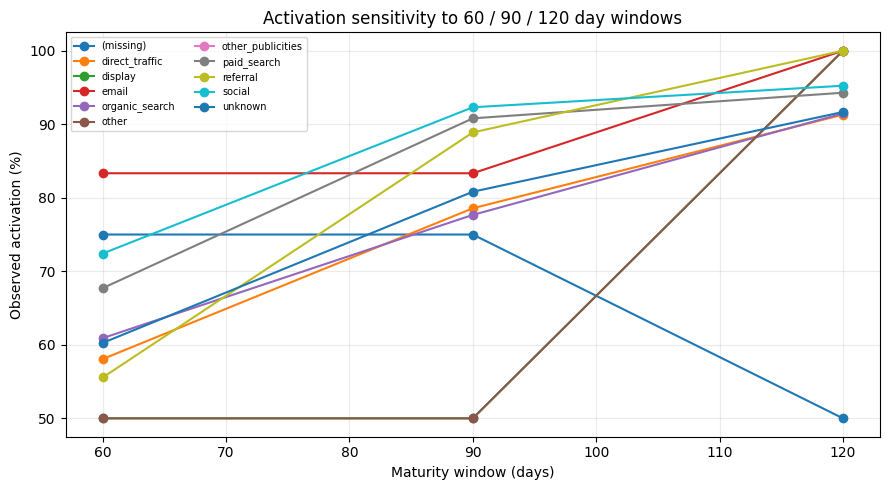

In [5]:
display(logit)
display(window_sensitivity.pivot(index="origin", columns="window_days", values="activation_pct"))
fig, ax = plt.subplots(figsize=(9, 5))
for origin, grp in window_sensitivity.groupby("origin"):
    ax.plot(grp["window_days"], grp["activation_pct"], marker="o", label=origin)
ax.set_xlabel("Maturity window (days)")
ax.set_ylabel("Observed activation (%)")
ax.set_title("Activation sensitivity to 60 / 90 / 120 day windows")
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

## 5. Acquisition quality and sales-cycle outcomes

In [6]:
display(conversion_lead)
display(conversion_segment)
display(close_days)

,lead_type,qualified_leads,closed_leads,conversion_pct
0,(missing),7164,6,0.083752
1,online_medium,332,332,100.000000
2,online_big,126,126,100.000000
3,industry,123,123,100.000000
4,offline,104,104,100.000000
5,online_small,77,77,100.000000
6,online_beginner,57,57,100.000000
7,online_top,14,14,100.000000
8,other,3,3,100.000000


,business_segment,qualified_leads,closed_leads,conversion_pct
0,(missing),7159,1,0.013968
1,home_decor,105,105,100.000000
2,health_beauty,93,93,100.000000
3,car_accessories,77,77,100.000000
4,household_utilities,71,71,100.000000
5,construction_tools_house_garden,69,69,100.000000
6,audio_video_electronics,64,64,100.000000
7,computers,34,34,100.000000
8,pet,30,30,100.000000
9,food_supplement,28,28,100.000000


,origin,deal_rows,median_days_to_close,mean_days_to_close
0,(missing),14,7.5,49.214286
1,direct_traffic,56,10.0,31.125000
2,display,6,8.5,10.333333
3,email,15,21.0,52.200000
4,organic_search,270,14.5,50.192593
5,other,4,9.0,15.250000
6,other_publicities,3,35.0,39.333333
7,paid_search,195,15.0,56.600000
8,referral,24,18.5,32.541667
9,social,75,30.0,60.960000


## 6. Marketplace value and concentration

GMV is delivered item-price value in BRL, not profit or recognized revenue. Concentration is measured on linked mature sellers only; unlinked sellers are outside the observed distribution.

,linked_mature_sellers_with_observed_gmv,total_delivered_gmv_brl,top_10_sellers_gmv_brl,top_10_share_pct,zero_gmv_sellers,zero_gmv_share_pct,gini
0,340,330080.56,159848.57,48.427139,58,17.058824,0.793494


,check,value,detail
0,purchase_window_gmv_all_statuses_brl,336683.900000,Linked mature sellers; item price; all order s...
1,purchase_window_gmv_delivered_only_brl,330080.560000,Linked mature sellers; delivered status only
2,all_status_vs_delivered_gap_brl,6603.340000,All-status item price minus delivered-status i...
3,payment_vs_item_price_plus_freight_within_R$1_pct,99.747631,98416/98665 orders within R$1.00; only orders ...
4,payment_vs_item_price_plus_freight_within_R$0....,99.613845,98284/98665 orders within R$0.01; only orders ...
5,payment_reconciliation_comparable_orders,98665.000000,"Orders with non-null item, freight and payment..."


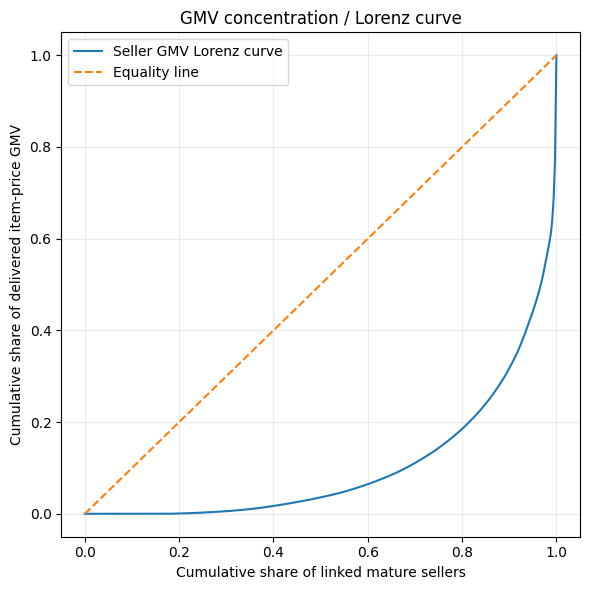

In [7]:
display(gmv_concentration)
display(payment)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(lorenz["seller_share_pct"] / 100, lorenz["cumulative_gmv_share_pct"] / 100, label="Seller GMV Lorenz curve")
ax.plot([0,1],[0,1], linestyle="--", label="Equality line")
ax.set_xlabel("Cumulative share of linked mature sellers")
ax.set_ylabel("Cumulative share of delivered item-price GMV")
ax.set_title("GMV concentration / Lorenz curve")
ax.legend()
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

## 7. Pipeline-generated charts

The static figures below are generated from the same current run as the CSV outputs.

activation_forest_by_origin.png


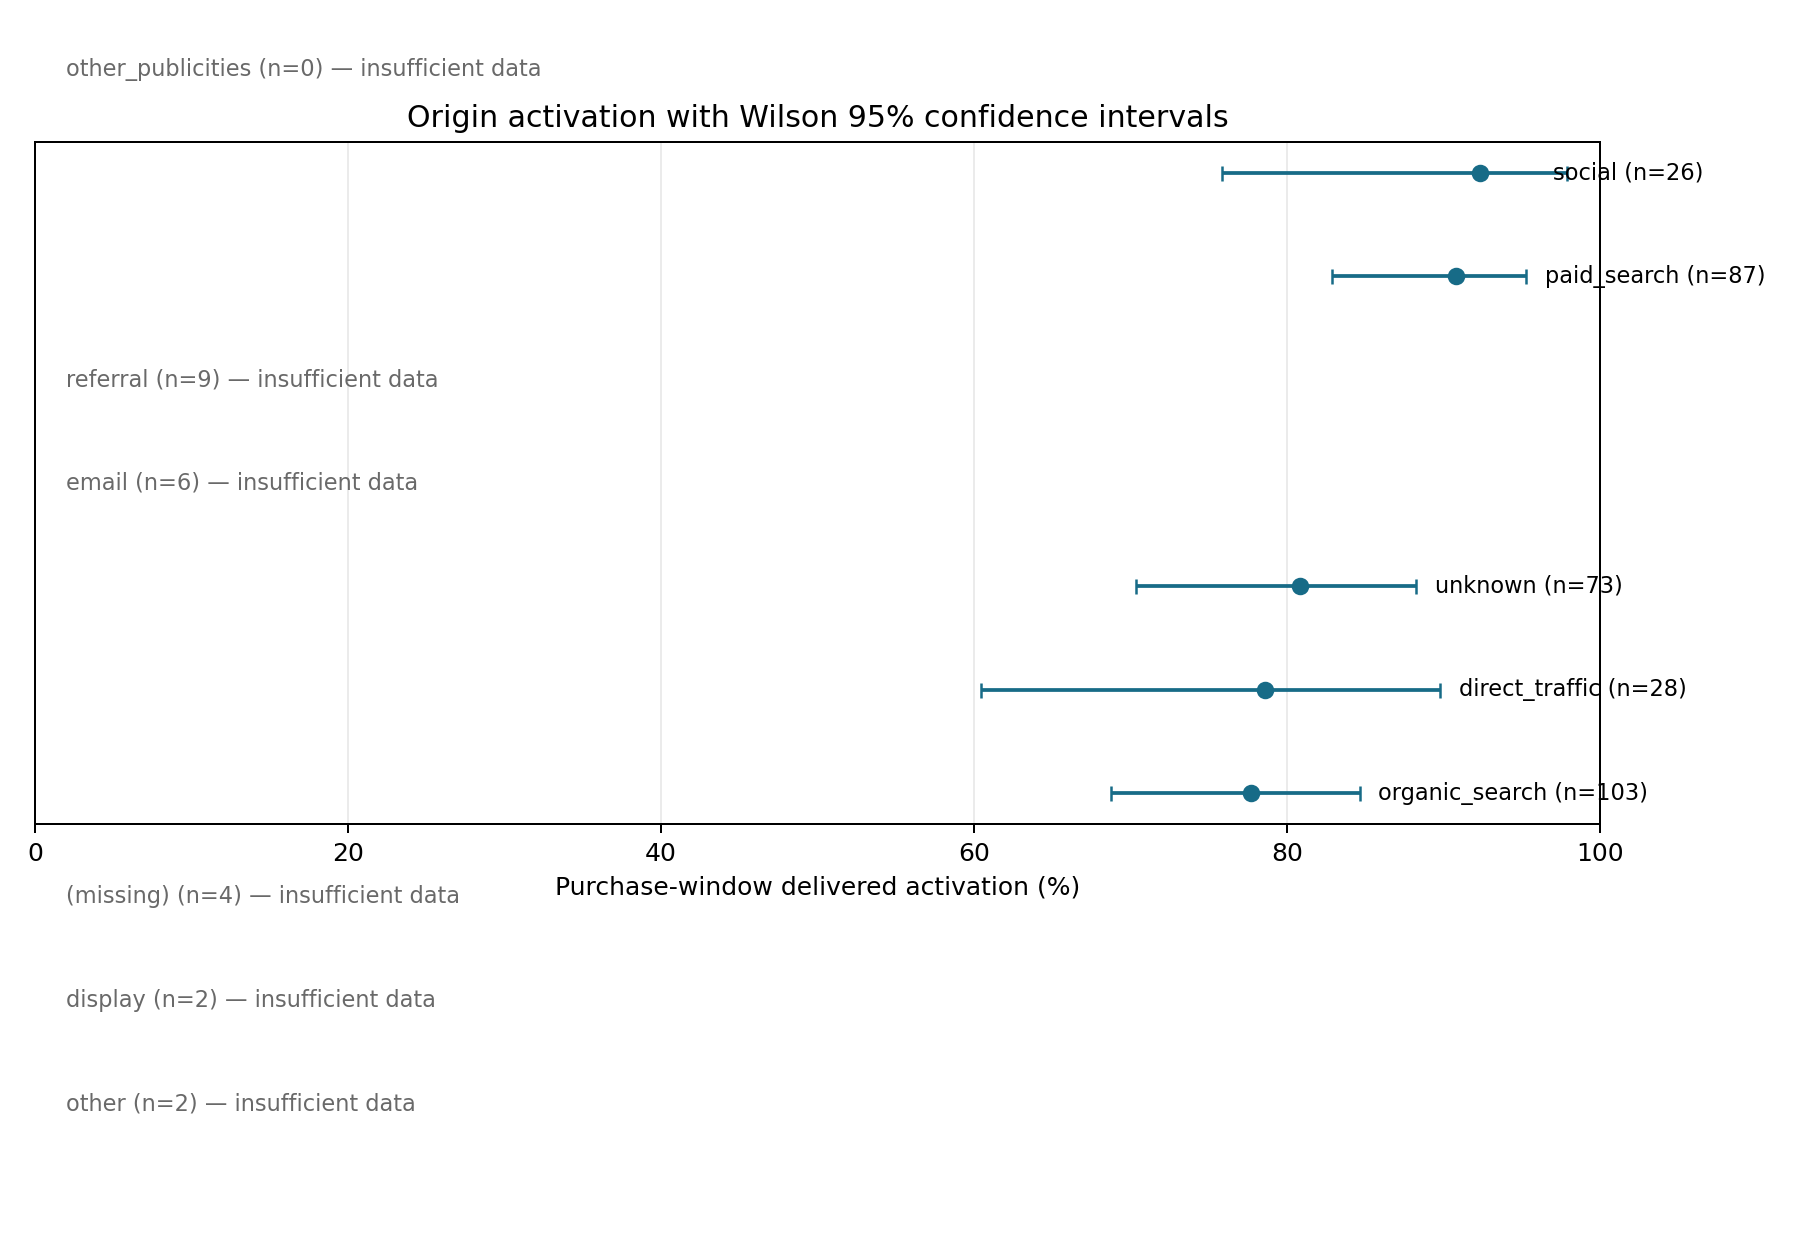

cumulative_activation_by_day.png


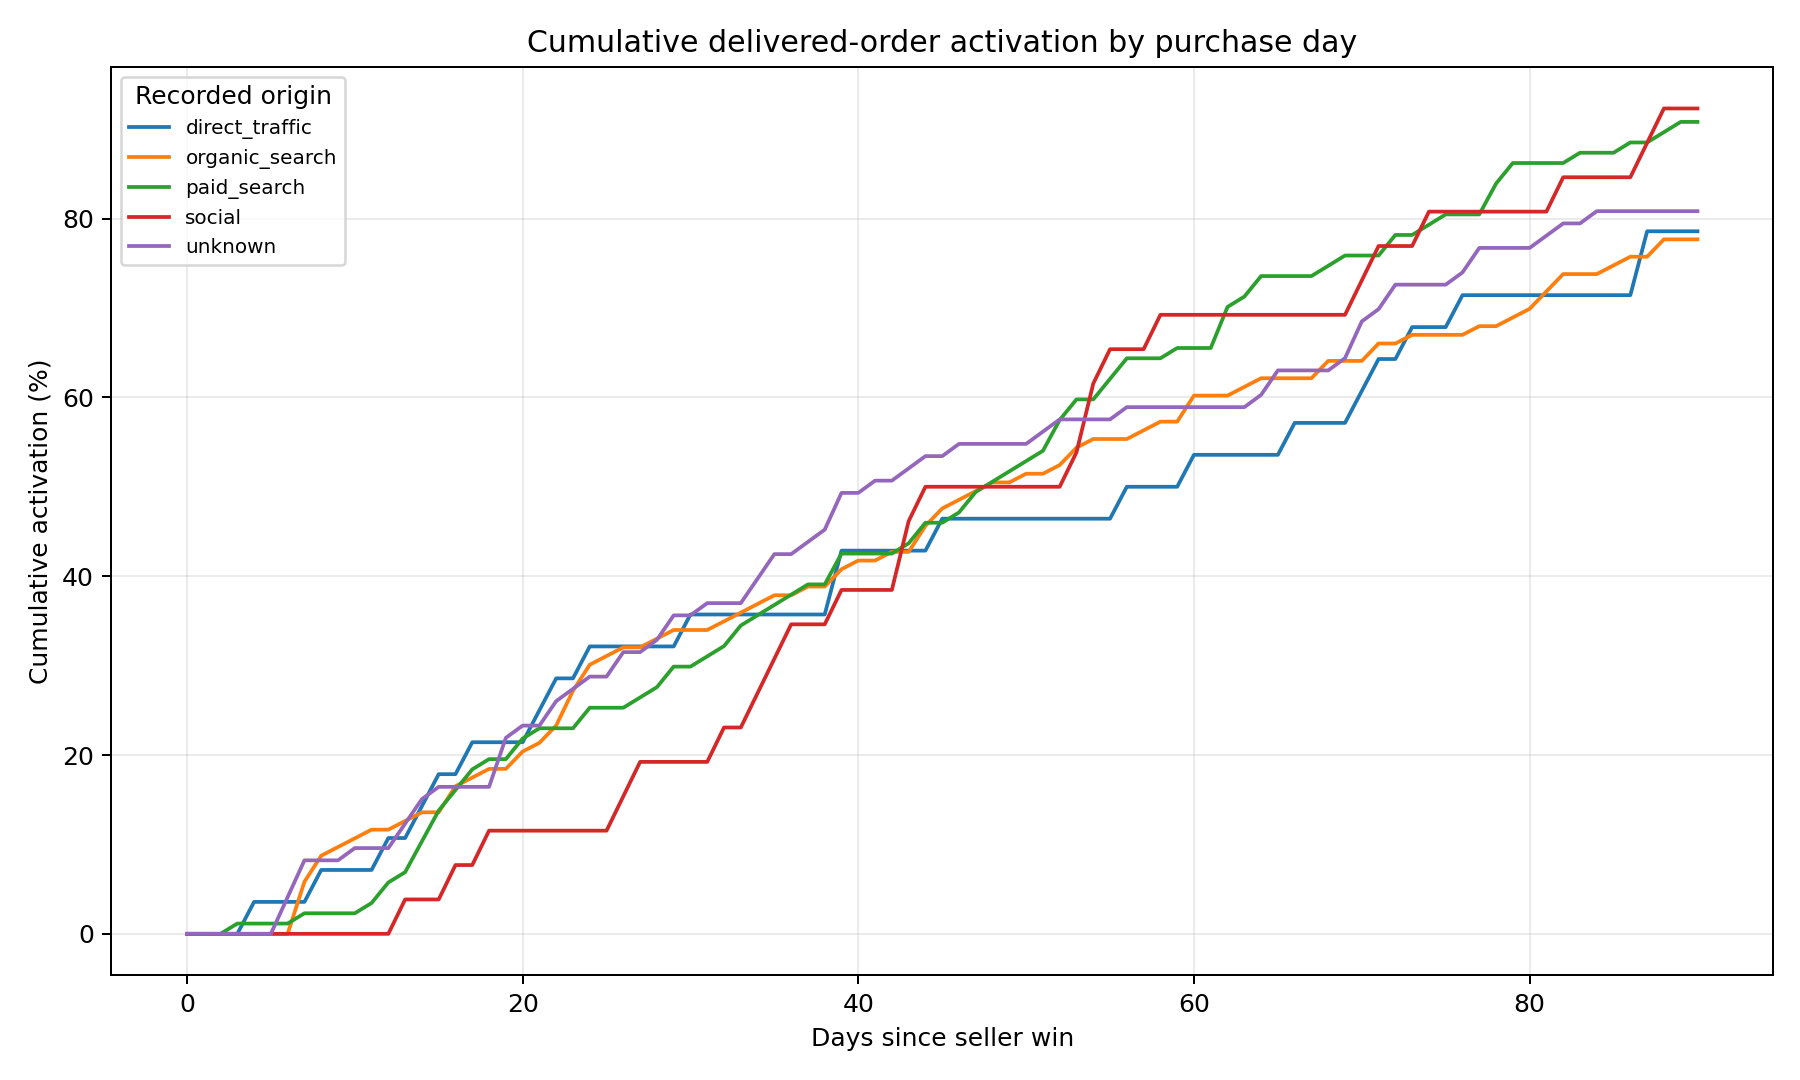

gmv_lorenz_curve.png


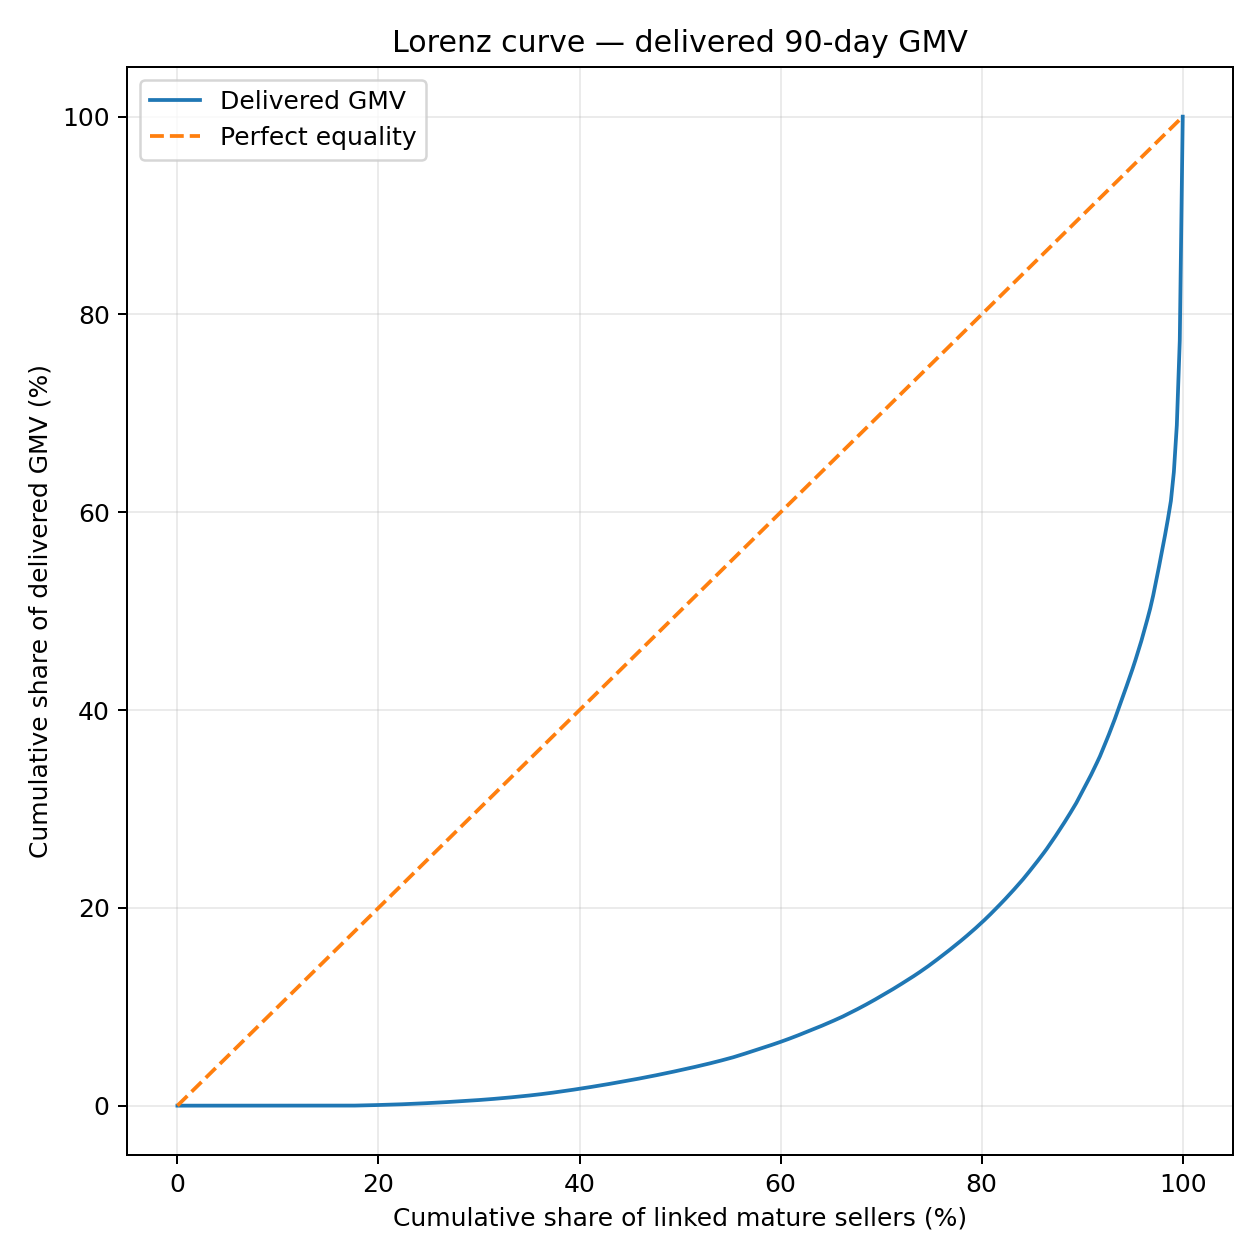

seller_linkage_rate_by_origin.png


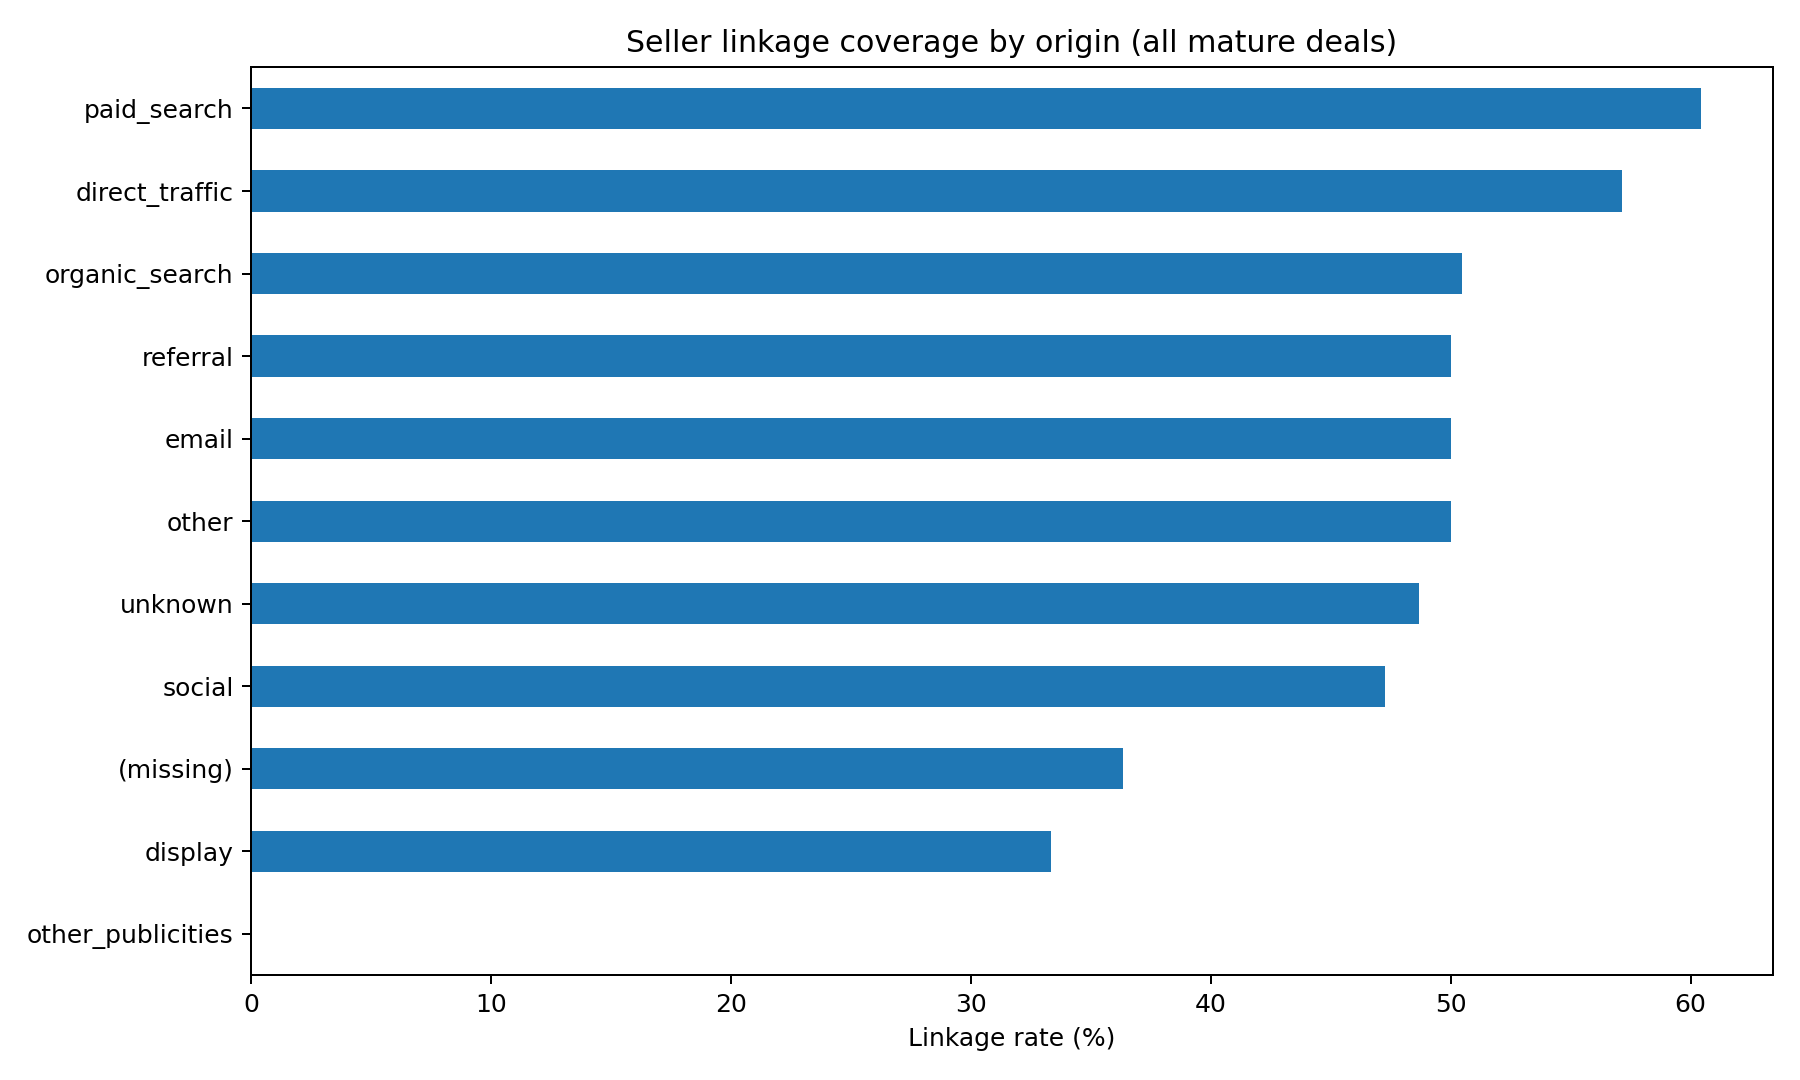

In [8]:
from IPython.display import Image, display as ipy_display
for filename in ["activation_forest_by_origin.png", "cumulative_activation_by_day.png", "gmv_lorenz_curve.png", "seller_linkage_rate_by_origin.png"]:
    path = CHARTS / filename
    if path.exists():
        print(filename)
        ipy_display(Image(filename=str(path)))

## 8. Interpretation and limits

- Use the Holm-adjusted pairwise result, not unadjusted p-values, when describing origin contrasts.
- Do not reallocate channel budget on the observed association alone; an experiment or holdout is needed.
- The missing seller-ID crosswalk, channel spend, seller registration date and mature/at-risk cohort tracking are the highest-value data additions.
- Results describe the supplied historical snapshot, not current seller behaviour.